# Statistical Analysis of the Titanic Dataset
Team members: Norah Alsuwailem, Raghad Alasmari, Fahad Al-Nahi, Rawan Alsubaie

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Task 1: Dataset exploration

In [4]:
df = pd.read_csv("titanic.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [6]:
df.shape

(891, 12)

In [7]:
df.columns.tolist()

['PassengerId',
 'Survived',
 'Pclass',
 'Name',
 'Sex',
 'Age',
 'SibSp',
 'Parch',
 'Ticket',
 'Fare',
 'Cabin',
 'Embarked']

In [8]:
df.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [9]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


1. The dataset has 891 rows and 12 columns.
2. Columns: PassengerId, Survived, Pclass, Name, Sex, Age, SibSp, Parch, Ticket, Fare, Cabin, Embarked.
3. Five columns are integers, two are floats (Age, Fare) and five are text (Name, Sex, Ticket, Cabin, Embarked).
4. Missing values: Age has 177, Cabin has 687 and Embarked has 2. The other columns have no missing values.
5. The dataset has information about 891 passengers on the Titanic. Each row is one passenger. The columns include age, sex, ticket class, fare and family members on board. The Survived column shows if the passenger survived (1) or not (0). Some columns have missing values, so the data needs cleaning before modeling.

# Task 2: Variable classification

| Variable | Numerical / Categorical | Type |
|---|---|---|
| PassengerId | Categorical | Nominal |
| Survived | Categorical | Nominal |
| Pclass | Categorical | Ordinal |
| Name | Categorical | Nominal |
| Sex | Categorical | Nominal |
| Age | Numerical | Continuous |
| SibSp | Numerical | Discrete |
| Parch | Numerical | Discrete |
| Ticket | Categorical | Nominal |
| Fare | Numerical | Continuous |
| Cabin | Categorical | Nominal |
| Embarked | Categorical | Nominal |

PassengerId, Survived and Pclass are stored as numbers, but they are labels and not real quantities, so we classified them as categorical.

# Task 3: Features and Target

1. The target variable is Survived.
2. The input features are the other columns: Pclass, Sex, Age, SibSp, Parch, Fare, Embarked, and also PassengerId, Name, Ticket and Cabin.
3. The target is called the dependent variable because its value depends on the other variables. It is the result we want to predict.
4. The other variables are independent because they are the inputs we use to predict the target, and they do not depend on it.

# Task 4: Population and sampling

In [10]:
ransam = df.sample(frac=0.3, random_state=42)
train, stratified_sample = train_test_split(df, test_size=0.3, stratify=df["Survived"], random_state=42)
print("Population:", len(df))
print("Random sample:", len(ransam))
print("Stratified:", len(stratified_sample))

Population: 891
Random sample: 267
Stratified: 268


In [11]:
print(df["Survived"].value_counts(normalize=True))
print(ransam["Survived"].value_counts(normalize=True))
print(stratified_sample["Survived"].value_counts(normalize=True))

Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64
Survived
0    0.588015
1    0.411985
Name: proportion, dtype: float64
Survived
0    0.615672
1    0.384328
Name: proportion, dtype: float64


1. The population is the whole Titanic dataset (891 passengers).
2. The sample is a part of the population. Here we took two samples, each about 30% of the data.
3. The population has 891 rows, the random sample has 267 rows and the stratified sample has 268 rows.
4. The stratified sample. In the population 61.6% did not survive and 38.4% survived. The stratified sample has almost the same (61.6% and 38.4%), but the random sample is a bit different (58.8% and 41.2%).
5. The model learns from the sample, so the sample should look like the real data. If it is not representative, the model will be biased and will not work well on new data.

# Task 5: Descriptive statistics

We selected Age, Fare and SibSp

In [12]:
col = ["Age", "Fare", "SibSp"]
stats = pd.DataFrame({
    "Mean": df[col].mean(),
    "Median": df[col].median(),
    "Mode": df[col].mode().iloc[0],
    "Min": df[col].min(),
    "Max": df[col].max(),
    "Range": df[col].max() - df[col].min(),
    "Variance": df[col].var(),
    "Std": df[col].std()
})
stats.round(2)

,Mean,Median,Mode,Min,Max,Range,Variance,Std
Age,29.70,28.00,24.00,0.42,80.00,79.58,211.02,14.53
Fare,32.20,14.45,8.05,0.00,512.33,512.33,2469.44,49.69
SibSp,0.52,0.00,0.00,0.00,8.00,8.00,1.22,1.10


1. Fare has the highest average (32.20).
2. Fare has the greatest variability. Its standard deviation is 49.69 and its variance is 2469.44.
3. For Age the mean and median are close (29.70 and 28). For Fare they are not close (32.20 and 14.45). For SibSp the mean is 0.52 and the median is 0.
4. Age is almost symmetric because the mean and median are close. Fare and SibSp are right skewed because the mean is higher than the median.

# Task 6: Distribution and outlier analysis

We chose Age and Fare

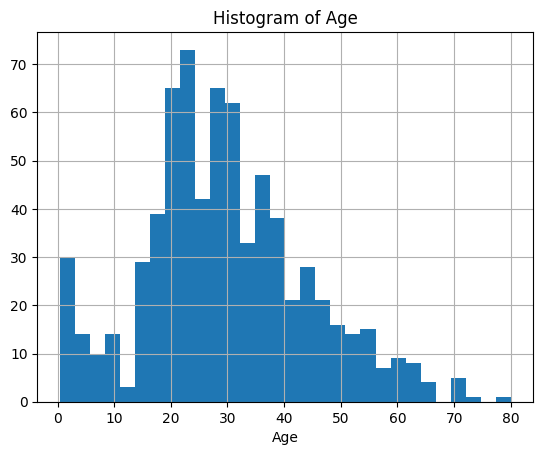

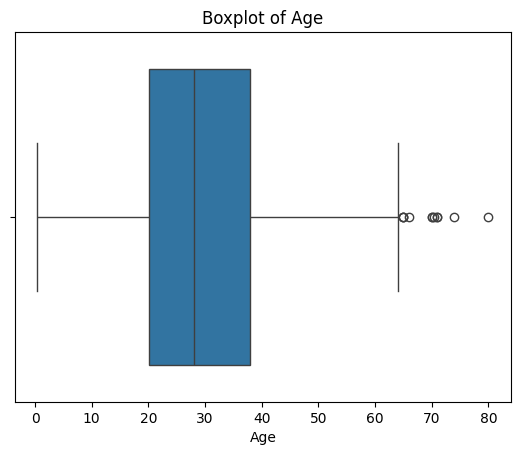

In [14]:
df["Age"].hist(bins=30)
plt.title("Histogram of Age")
plt.xlabel("Age")
plt.show()
sns.boxplot(x=df["Age"])
plt.title("Boxplot of Age")
plt.show()

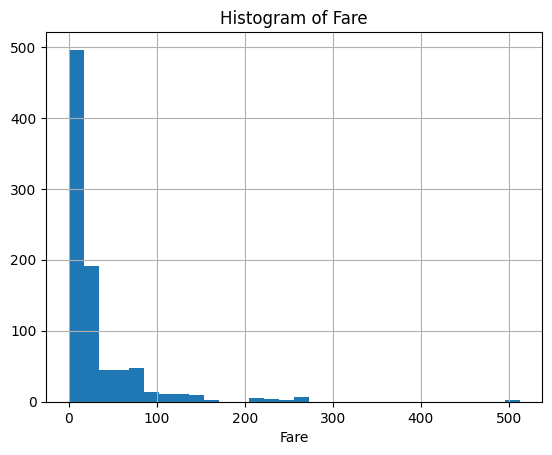

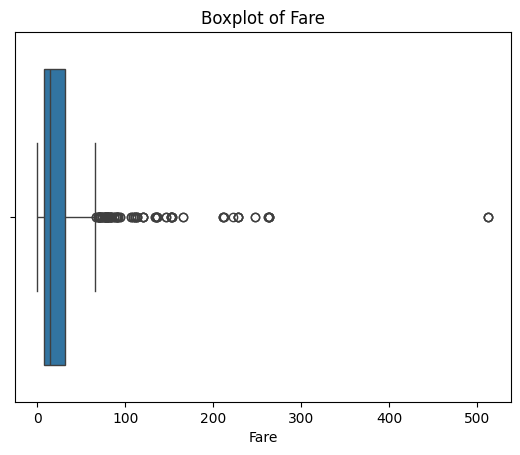

In [15]:
df["Fare"].hist(bins=30)
plt.title("Histogram of Fare")
plt.xlabel("Fare")
plt.show()
sns.boxplot(x=df["Fare"])
plt.title("Boxplot of Fare")
plt.show()

1. Age is approximately symmetric. Fare is skewed to the right.
2. Yes. Age has a few outliers (passengers older than about 65). Fare has many outliers, and some fares are above 500.
3. The mean is more affected by outliers.
4. In the Fare histogram most values are low but there is a long tail on the right. The boxplot shows many points far from the box. These high values pull the mean up to 32.20, while the median stays at 14.45. For Age there are only a few outliers, so the mean and median are almost the same.

# Task 7: Correlation and covariance analysis

In [16]:
num = df.drop(columns="PassengerId").select_dtypes(include="number")
corr = num.corr()
corr.round(2)

,Survived,Pclass,Age,SibSp,Parch,Fare
Survived,1.00,-0.34,-0.08,-0.04,0.08,0.26
Pclass,-0.34,1.00,-0.37,0.08,0.02,-0.55
Age,-0.08,-0.37,1.00,-0.31,-0.19,0.10
SibSp,-0.04,0.08,-0.31,1.00,0.41,0.16
Parch,0.08,0.02,-0.19,0.41,1.00,0.22
Fare,0.26,-0.55,0.10,0.16,0.22,1.00


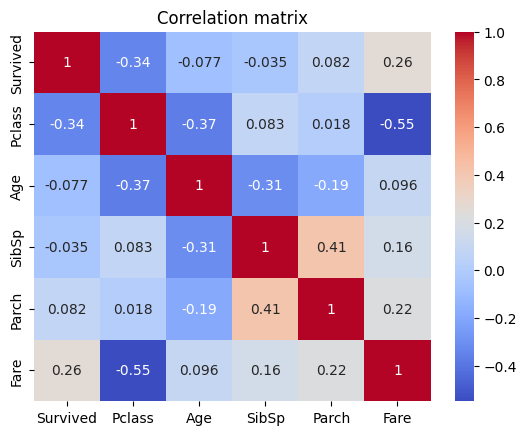

In [17]:
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation matrix")
plt.show()

In [18]:
cov = num.cov()
cov.round(2)

,Survived,Pclass,Age,SibSp,Parch,Fare
Survived,0.24,-0.14,-0.55,-0.02,0.03,6.22
Pclass,-0.14,0.70,-4.50,0.08,0.01,-22.83
Age,-0.55,-4.50,211.02,-4.16,-2.34,73.85
SibSp,-0.02,0.08,-4.16,1.22,0.37,8.75
Parch,0.03,0.01,-2.34,0.37,0.65,8.66
Fare,6.22,-22.83,73.85,8.75,8.66,2469.44


We removed PassengerId because it is only an ID.

1. SibSp and Parch have the strongest positive correlation (0.41). The strongest correlation overall is between Pclass and Fare, but it is negative (-0.55).
2. Pclass and Parch (0.02), Survived and SibSp (-0.04), Survived and Age (-0.08).
3. Both show how two variables change together. Covariance depends on the units of the variables and has no fixed range. Correlation is standardized and is always between -1 and 1.
4. Correlation is easier to interpret because it has a fixed range, so we can compare variables directly. For example the covariance of Age and Fare is 73.85, which looks large, but their correlation is only 0.10.

# Task 8: Statistical insights

1. Fare has the largest spread and the highest average (mean 32.20, standard deviation 49.69).
2. Fare contains many outliers and is right skewed.
3. Pclass and Fare are related (-0.55). First class passengers paid higher fares.
4. SibSp and Parch are positively correlated (0.41), so families travelled together.
5. Age, Cabin and Embarked have missing values and need preprocessing. Sex and Embarked are text and need encoding.

# Task 9: Statistics for ML

In [19]:
print(df.groupby("Sex")["Survived"].mean())
print(df.groupby("Pclass")["Survived"].mean())

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64
Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


1. Sex. About 74% of females survived but only 19% of males. Pclass is also useful, it has the strongest correlation with Survived in the matrix (-0.34).
2. Cabin, because 687 of 891 values are missing. We would also remove PassengerId, Name and Ticket because they are different for almost every passenger and do not help prediction.
3. Fare and Age, because they have the largest variance in the covariance matrix (2469.44 and 211.02). If the data is scaled first, Pclass and Fare would contribute the most because they have the strongest correlation (-0.55).
4. Fill missing Age with the median, fill missing Embarked with the mode and drop Cabin. Encode Sex and Embarked as numbers. Scale the numerical features, especially Fare because it is skewed and has outliers.